In [ ]:
# Tester at Frost API fungerer

import requests
from pathlib import Path

# Leser Client ID fra tekstfilen på PC-en din
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API-endepunktet for observasjoner
url = "https://frost.met.no/observations/v0.jsonld"

# Velger værstasjon, tidsperiode og værdata
parameters = {
    "sources": "SN17850",
    "referencetime": "2024-01-01/2024-01-03",
    "elements": "air_temperature"
}

# Sender forespørselen til Frost API
response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

# Viser resultatet av testen
print("Statuskode:", response.status_code)

if response.status_code == 200:
    print("Frost API fungerer!")
    print(response.json()["data"][:1])
else:
    print(response.text[:1000]) 
    



Statuskode: 200
Frost API fungerer!
[{'sourceId': 'SN17850:0', 'referenceTime': '2024-01-01T00:00:00.000Z', 'observations': [{'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 1}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 2}, {'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 50}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 2}, {'elementId': 'air_temperature', 'value': -3.7, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'PT1H', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}]}]


## Task 1: Temperature
### Following the example from frost.met.no on how to get the data when using Python

In [17]:
# Requesting the daily mean air temperature for 2025

print("Starting Frost request...")

import requests
from pathlib import Path

# Read Client ID from file
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API endpoint
url = "https://frost.met.no/observations/v0.jsonld"

## Parameters for Ås and all of 2025
parameters = {
    "sources": "SN17850",
    "referencetime": "2025-01-01/2026-01-01",
    "elements": "mean(air_temperature P1D)"
}

# Send request to Frost API
response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

print("Frost response received!")

# Check response status
print("Status code:", response.status_code)

if response.status_code == 200:
    data = response.json()["data"]
    print("Frost API works!")
    print("Number of observations:", len(data))

    ## Extract dates and daily mean temperatures
    dates = []
    temperatures = []

    for item in data:
        dates.append(item["referenceTime"])
        temperatures.append(item["observations"][0]["value"])

    print("Temperatures extracted:", len(temperatures))

else:
    print("Error:", response.text[:1000]) 

Starting Frost request...
Frost response received!
Status code: 200
Frost API works!
Number of observations: 365
Temperatures extracted: 365


### Make plot of air temperature: 

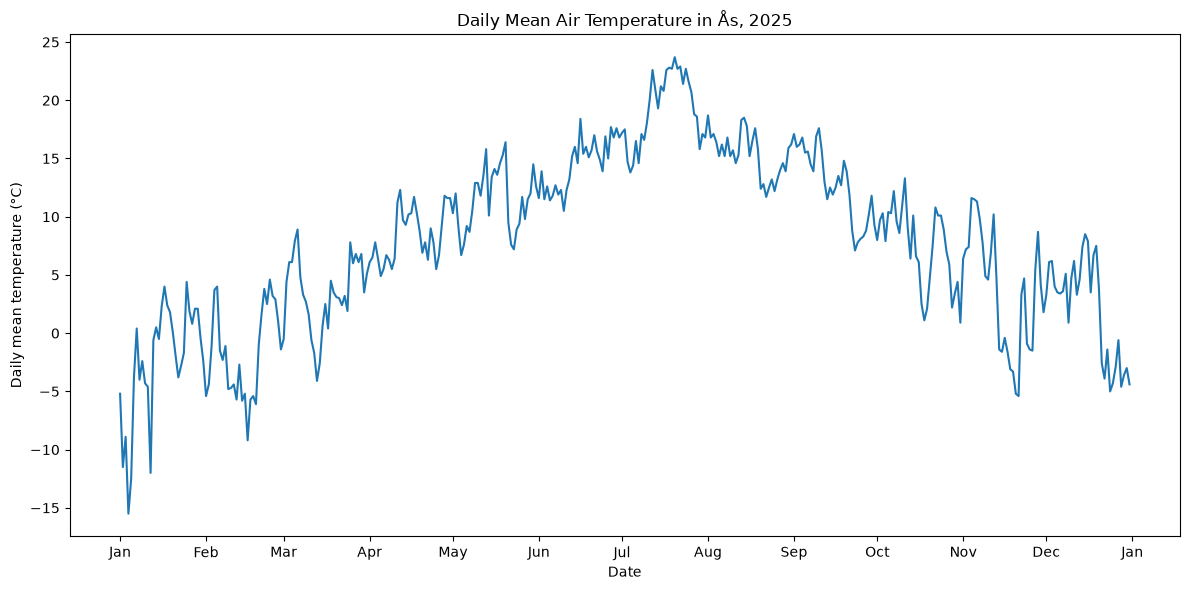

In [18]:
import matplotlib.pyplot as plt

# Plot daily mean temperature for 2025
plt.figure(figsize=(12, 6))
plt.plot(dates, temperatures)

plt.xlabel("Date")
plt.ylabel("Daily mean temperature (°C)")
plt.title("Daily Mean Air Temperature in Ås, 2025")

# Show one date label per month
# --> tried it without this part and the x-axis was very crowded, so I added this to make it more readable 
import matplotlib.dates as mdates

plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))




plt.tight_layout() #Automatically adjusts the spacing around the graph
plt.show()

### Calculate the mean, median, min and max temperature for this year (2025)

In [19]:
import statistics

## Calculate summary statistics for 2025:
mean_temp = statistics.mean(temperatures)
median_temp = statistics.median(temperatures)
min_temp = min(temperatures)
max_temp = max(temperatures)

### Make the summary table containing the summary statistics

In [20]:
## Display summary table: 

print("Summary of daily mean air temperature in Ås, 2025:")
print("-------------------------------------------------")
print("Mean temperature:", round(mean_temp, 2), "°C")
print("Median temperature:", round(median_temp, 2), "°C")
print("Minimum temperature:", round(min_temp, 2), "°C")
print("Maximum temperature:", round(max_temp, 2), "°C")

Summary of daily mean air temperature in Ås, 2025:
-------------------------------------------------
Mean temperature: 7.87 °C
Median temperature: 8.3 °C
Minimum temperature: -15.5 °C
Maximum temperature: 23.7 °C


## Task 2: Precipitation

In [21]:
# Requesting daily precipitation for 2025

import requests
from pathlib import Path

# Read Client ID from file
client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

# Frost API endpoint
url = "https://frost.met.no/observations/v0.jsonld"

# Parameters for Ås and all of 2025
parameters = {
    "sources": "SN17850",
    "referencetime": "2025-01-01/2026-01-01",
    "elements": "sum(precipitation_amount P1D)"
}

# Send request to Frost API
precipitation_response = requests.get(
    url,
    params=parameters,
    auth=(client_id, ""),
    timeout=30
)

# Check response status
print("Status code:", precipitation_response.status_code)

if precipitation_response.status_code == 200:
    precipitation_data = precipitation_response.json()["data"]

    # Extract dates and daily precipitation amounts
    precipitation_dates = []
    precipitation_values = []

    for item in precipitation_data:
        precipitation_dates.append(item["referenceTime"])
        precipitation_values.append(item["observations"][0]["value"])

    print("Frost API works!")
    print("Number of precipitation observations:", len(precipitation_values))

else:
    print("Error:", precipitation_response.text[:1000])


Status code: 200
Frost API works!
Number of precipitation observations: 365


### Create a new plot that shows both the temperature from task 1 and the precipitation in the same plot
Creating one figure showing both the temperature from task 1 and the precipitation from task 2.
Going to use two y-axes; one for temperature and one for precipitation. 

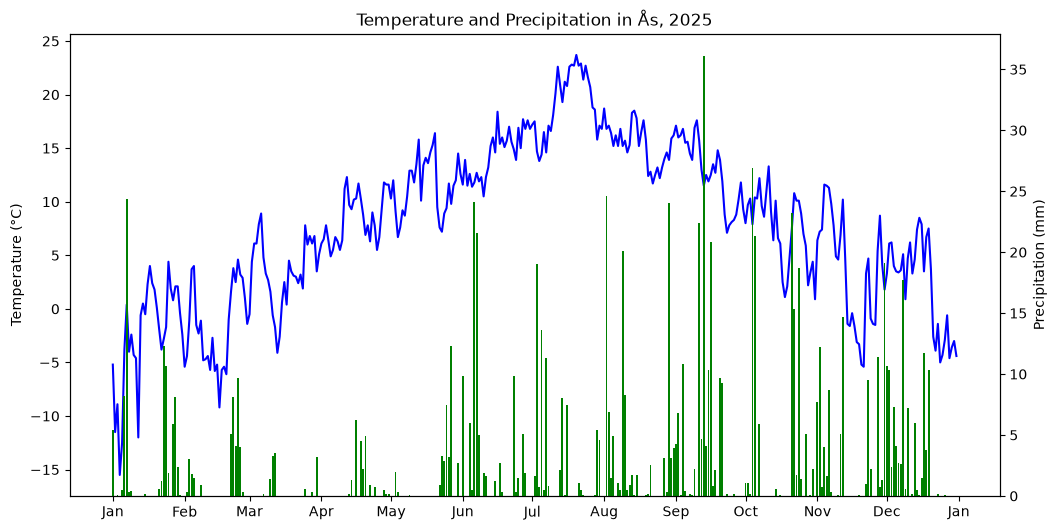

In [24]:
import matplotlib.pyplot as plt

# Create the plot
fig, ax1 = plt.subplots(figsize=(12, 6))  # making the first y-axis for temperature
# subplots(figsize=(12, 6)) Creates a figure in which we will plot our graph

# Plot temperature as a line
ax1.plot(dates, temperatures, color="blue", label="Temperature")
ax1.set_ylabel("Temperature (°C)")

# Plot precipitation as bars
ax2 = ax1.twinx() # making the other y-axis for precipitation
ax2.bar(precipitation_dates, precipitation_values, color="green", label="Precipitation")
ax2.set_ylabel("Precipitation (mm)")


# Show one date label per month
"""Matplotlib tries to display too many dates, causing them to overlap
To fix this we can use the MonthLocator and DateFormatter to show only one date label per month."""
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))



plt.title("Temperature and Precipitation in Ås, 2025")
plt.show()

--> A line graph works best for temperature (blue)
--> A bar chart works best for precipitation (green)